# 3. Zonas de ozono y alerta del día siguiente: PCA, clusterización y clasificación

**Preguntas.**
1. ¿Las 26 estaciones raspadas se comportan igual, o hay **zonas** con patrones de ozono distintos? (reducción dimensional + clusterización)
2. Con lo que se sabe hoy, ¿se puede **clasificar** si mañana el máximo de la red rebasará el límite horario de la NOM (90 ppb)? (clasificación)

**Datos.** Las tablas que genera `01_scraping_sinaica_navegador.ipynb` en `datos_scraping/salida/` (todo viene del web scraping de SINAICA).

| Sección | Rubro | Qué hace |
|---|---|---|
| 1. Perfil de cada estación | — | Resume cada estación en 288 números: su promedio de O₃ por mes (12) × hora (24) |
| 2. PCA | Reducción dimensional | Comprime los 288 números en pocos componentes que se pueden interpretar |
| 3. K-means | Clusterización | Agrupa las estaciones en zonas con el mismo patrón de ozono |
| 4. Clasificación | Clasificación | Regresión logística y bosque aleatorio para "¿mañana > 90 ppb?", con partición temporal |

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
                             silhouette_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
DIR = Path("datos_scraping")
SALIDA = DIR / "salida"
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
RES = Path("resultados"); RES.mkdir(exist_ok=True)
SEMILLA = 0
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})

h = pd.read_csv(SALIDA / "o3_horario_estaciones.csv.gz", usecols=["fecha", "hora", "estacion", "valor", "flag"],
                dtype={"fecha": str, "estacion": str})
h = h[~h["flag"].isin(["rango", "pico"])].copy()      # mismas exclusiones que el resto del proyecto
h["mes"] = h["fecha"].str[5:7].astype(int)
cat = pd.read_csv(DIR / "catalogos" / "estaciones.csv").set_index("cve_estac")
nombre = lambda c: f"{cat['nom_estac'].get(c, c)} ({c})"
print(f"Valores horarios válidos: {len(h):,} | estaciones: {h['estacion'].nunique()} | "
      f"periodo: {h['fecha'].min()} a {h['fecha'].max()}")

Valores horarios válidos: 2,103,209 | estaciones: 26 | periodo: 2015-01-01 a 2026-11-08


## 1. Perfil de cada estación

Cada estación se describe con su **promedio de O₃ para cada combinación mes × hora** (12 × 24 = 288 variables), usando todo el periodo. Ese perfil captura a la vez el nivel (cuánto ozono), el ciclo diario (a qué hora sube) y la temporada (en qué meses).

Solo entran estaciones con al menos 2 años de datos, para que el promedio sea estable.

In [2]:
horas_est = h.groupby("estacion").size()
validas = horas_est[horas_est >= 2 * 365 * 24 * 0.75].index
perfil = h[h["estacion"].isin(validas)].groupby(["estacion", "mes", "hora"])["valor"].mean().unstack(["mes", "hora"])
huecos = int(perfil.isna().sum().sum())
perfil = perfil.fillna(perfil.mean())                 # casillas mes-hora sin dato: promedio de la red
print(f"Matriz de perfiles: {perfil.shape[0]} estaciones x {perfil.shape[1]} variables (mes x hora) | "
      f"casillas rellenadas: {huecos}")
print("Excluidas por tener < 2 años de datos:", sorted(set(horas_est.index) - set(validas)) or "ninguna")
display(perfil.mean(axis=1).sort_values(ascending=False).rename("O₃ promedio (ppb)").round(1).to_frame().T)

Matriz de perfiles: 26 estaciones x 288 variables (mes x hora) | casillas rellenadas: 0
Excluidas por tener < 2 años de datos: ninguna


estacion,AJM,CUA,PED,TAH,CCA,UAX,SAC,BJU,FAR,NEZ,...,VIF,ACO,ATI,TLI,CUT,SAG,LLA,LPR,MER,XAL
O₃ promedio (ppb),41.5,35.1,34.7,33.7,33.3,32.9,32.1,31.3,31.0,30.3,...,28.4,28.0,27.8,27.4,27.1,26.4,26.4,26.3,26.2,24.5


## 2. Reducción dimensional: PCA

Las 288 variables están muy correlacionadas (la hora 14 de mayo se parece a la hora 15 de mayo). El **análisis de componentes principales (PCA)** encuentra las pocas direcciones en las que las estaciones realmente difieren.

- Se **centra** cada variable pero **no se estandariza**: todas están en ppb, y estandarizar daría el mismo peso a las horas de la madrugada (casi sin ozono) que a la tarde, que es donde están las diferencias que importan.
- Se conservan los componentes que explican al menos el 90 % de la varianza.
- El signo de cada componente es arbitrario; se orienta para que valores positivos signifiquen "más ozono" (CP1) o "pico más tarde/más concentrado en la temporada seca" según su relación con el perfil.

Varianza explicada: CP1 65.8% | CP2 18.4% | CP3 6.6% | se conservan 3 componentes (90.8%)
Correlación CP1 con el O₃ promedio de la estación: 1.00


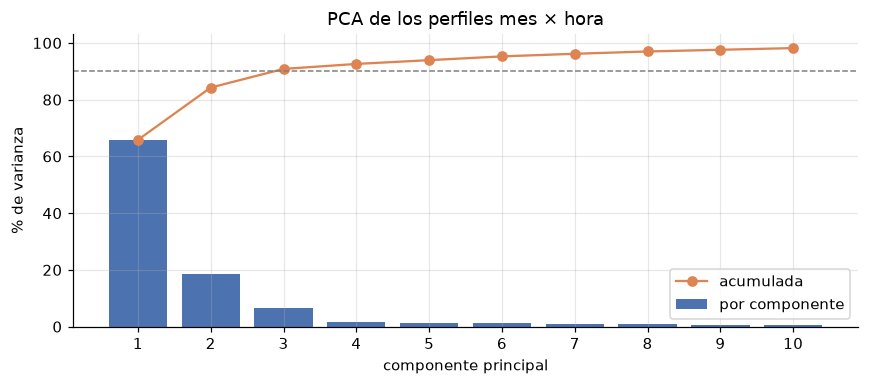

In [3]:
X = perfil.to_numpy()
pca = PCA(random_state=SEMILLA).fit(X)
var = pca.explained_variance_ratio_
n_comp = int(np.searchsorted(var.cumsum(), 0.90) + 1)
puntos = pca.transform(X)
cargas = pca.components_.copy()
for j in range(2):                                    # CP con signo interpretable: carga media positiva
    if cargas[j].mean() < 0 or (j == 1 and cargas[j][np.argmax(np.abs(cargas[j]))] < 0):
        cargas[j] *= -1; puntos[:, j] *= -1
nivel = perfil.mean(axis=1).to_numpy()
print(f"Varianza explicada: CP1 {var[0]:.1%} | CP2 {var[1]:.1%} | CP3 {var[2]:.1%} | "
      f"se conservan {n_comp} componentes ({var[:n_comp].sum():.1%})")
print(f"Correlación CP1 con el O₃ promedio de la estación: {np.corrcoef(puntos[:, 0], nivel)[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
k = min(10, len(var))
ax.bar(range(1, k + 1), var[:k] * 100, color="#4C72B0", label="por componente")
ax.plot(range(1, k + 1), var[:k].cumsum() * 100, "o-", color="#DD8452", label="acumulada")
ax.axhline(90, ls="--", color="gray", lw=1)
ax.set(xlabel="componente principal", ylabel="% de varianza", title="PCA de los perfiles mes × hora", xticks=range(1, k + 1))
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "10_pca_varianza.png", bbox_inches="tight"); plt.show()

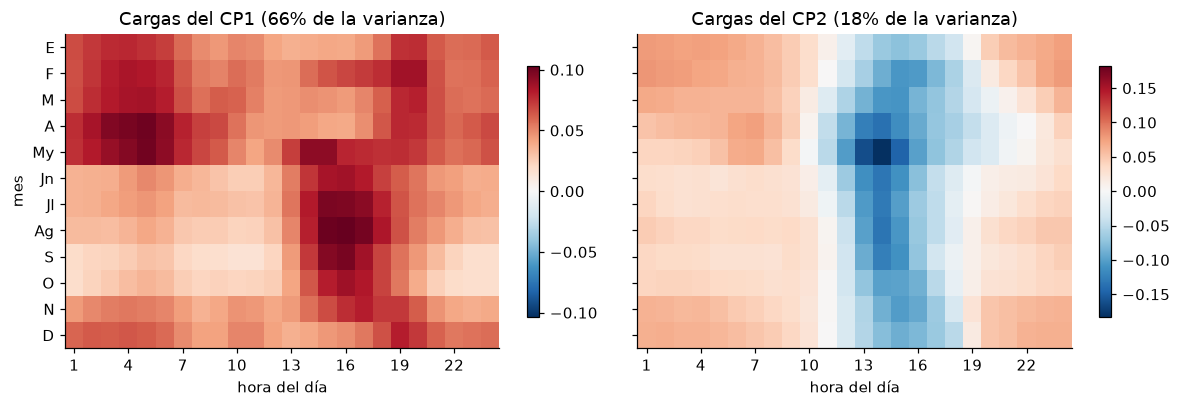

CP2, carga media por bloque de horas: {'1-9 h': 0.048, '10-17 h': -0.061, '18-24 h': 0.019}
Correlación CP2 con la razón madrugada/tarde: 0.61
CP2 más bajo: CCA, BJU, IZT, UAX, HGM | CP2 más alto: ATI, LPR, ACO, CUA, AJM


In [4]:
# Qué significa cada componente: sus cargas acomodadas como mes x hora
meses = ["E", "F", "M", "A", "My", "Jn", "Jl", "Ag", "S", "O", "N", "D"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for j, ax in enumerate(axs):
    m = cargas[j].reshape(12, 24)
    lim = np.abs(m).max()
    im = ax.imshow(m, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set(title=f"Cargas del CP{j + 1} ({var[j]:.0%} de la varianza)", xlabel="hora del día",
           xticks=range(0, 24, 3), xticklabels=range(1, 25, 3), yticks=range(12), yticklabels=meses)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8)
axs[0].set_ylabel("mes")
fig.tight_layout(); fig.savefig(FIG / "11_pca_cargas.png", bbox_inches="tight"); plt.show()

c2 = cargas[1].reshape(12, 24)
print("CP2, carga media por bloque de horas:",
      {"1-9 h": round(float(c2[:, :9].mean()), 3), "10-17 h": round(float(c2[:, 9:17].mean()), 3),
       "18-24 h": round(float(c2[:, 17:].mean()), 3)})
# Indicador físico: ozono de madrugada respecto al de la tarde (bajo = mucho NO local que "consume" el ozono de noche)
noche = perfil.loc[:, (slice(None), [1, 2, 3, 4, 5, 6])].mean(axis=1)
tarde = perfil.loc[:, (slice(None), [14, 15, 16])].mean(axis=1)
razon_noche_tarde = (noche / tarde).rename("O₃ madrugada / O₃ tarde")
print(f"Correlación CP2 con la razón madrugada/tarde: {np.corrcoef(puntos[:, 1], razon_noche_tarde)[0, 1]:.2f}")
s2 = pd.Series(puntos[:, 1], index=perfil.index).sort_values()
print("CP2 más bajo:", ", ".join(s2.index[:5]), "| CP2 más alto:", ", ".join(s2.index[-5:]))

## 3. Clusterización: K-means sobre los componentes

- **Algoritmo:** K-means sobre las coordenadas de los componentes conservados (no sobre las 288 variables: así el ruido de los componentes menores no influye).
- **Número de grupos (k):** se prueba k = 2 a 6 con dos criterios:
  - **Coeficiente de silueta:** qué tan cerca está cada estación de su grupo frente al grupo vecino (de −1 a 1; más alto es mejor).
  - **Estabilidad:** se repite la agrupación con un método distinto (clusterización jerárquica de Ward) y se comparan los grupos con el índice de Rand ajustado (1 = idénticos, 0 = al azar).
- **Regla:** se elige el k con mayor silueta **entre los estables** (Rand ajustado ≥ 0.8). Unos grupos que cambian al cambiar de método no son zonas reales.

In [5]:
Z = puntos[:, :n_comp]
pruebas = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEMILLA).fit(Z)
    wd = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(Z)
    pruebas.append({"k": k, "silueta": silhouette_score(Z, km.labels_),
                    "Rand ajustado vs Ward": adjusted_rand_score(km.labels_, wd.labels_), "inercia": km.inertia_})
pruebas = pd.DataFrame(pruebas).set_index("k")
estables = pruebas[pruebas["Rand ajustado vs Ward"] >= 0.8]
K = int((estables if len(estables) else pruebas)["silueta"].idxmax())
display(pruebas.round(3).T)

km = KMeans(n_clusters=K, n_init=50, random_state=SEMILLA).fit(Z)
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
print(f"k elegido = {K} (silueta {pruebas.loc[K, 'silueta']:.2f}) | "
      f"acuerdo K-means vs Ward (Rand ajustado): {adjusted_rand_score(km.labels_, ward.labels_):.2f}")

# Zonas numeradas de más a menos ozono y descritas por su ubicación
est = pd.DataFrame({"estacion": perfil.index, "grupo": km.labels_, "o3_promedio": nivel,
                    "CP1": puntos[:, 0], "CP2": puntos[:, 1], "razon_madrugada_tarde": razon_noche_tarde.to_numpy()}
                   ).join(cat[["nom_estac", "lat", "lon"]], on="estacion")
orden = est.groupby("grupo")["o3_promedio"].mean().sort_values(ascending=False).index
est["zona"] = est["grupo"].map({g: i + 1 for i, g in enumerate(orden)})
lat0, lon0 = est["lat"].mean(), est["lon"].mean()

def ubicacion(g):
    la, lo = g["lat"].mean() - lat0, g["lon"].mean() - lon0
    ns = "norte" if la > 0.04 else "sur" if la < -0.04 else "centro"
    eo = "oriente" if lo > 0.04 else "poniente" if lo < -0.04 else ""
    return (ns + ("-" + eo if eo else "")) if ns != "centro" or eo else "centro"

desc = est.groupby("zona").apply(ubicacion, include_groups=False)
# Nombres descriptivos para la solución de 3 zonas de esta corrida (si cambia k, se usa la ubicación media)
conocidas = {frozenset(["AJM", "CUA"]): "montaña sur-poniente"}
for z, g in est.groupby("zona"):
    s = frozenset(g["estacion"])
    if s in conocidas:
        desc[z] = conocidas[s]
    elif K == 3 and {"ACO", "CUT", "TLI"} <= s:
        desc[z] = "norte"
    elif K == 3 and {"BJU", "CCA", "UAX"} <= s:
        desc[z] = "centro, sur y oriente"
est["zona_nombre"] = est["zona"].map(lambda z: f"Zona {z} ({desc[z]})")
resumen_zonas = est.groupby("zona_nombre").agg(estaciones=("estacion", "size"),
                                               o3_promedio=("o3_promedio", "mean"),
                                               razon_madrugada_tarde=("razon_madrugada_tarde", "mean"),
                                               latitud=("lat", "mean"), longitud=("lon", "mean"),
                                               lista=("estacion", lambda s: ", ".join(sorted(s))))
display(resumen_zonas.round(1))
est.sort_values(["zona", "o3_promedio"], ascending=[True, False]).to_csv(RES / "zonas_estaciones.csv", index=False)

k,2,3,4,5,6
silueta,0.413,0.395,0.331,0.332,0.315
Rand ajustado vs Ward,0.183,1.000,0.656,0.655,0.588
inercia,81071.888,48786.077,35211.768,27763.436,22400.794


k elegido = 3 (silueta 0.40) | acuerdo K-means vs Ward (Rand ajustado): 1.00


,estaciones,o3_promedio,razon_madrugada_tarde,latitud,longitud,lista
zona_nombre,,,,,,
Zona 1 (montaña sur-poniente),2,38.3,0.3,19.3,-99.2,"AJM, CUA"
"Zona 2 (centro, sur y oriente)",13,31.2,0.2,19.4,-99.1,"BJU, CCA, FAR, GAM, HGM, IZT, MGH, NEZ, PED, S..."
Zona 3 (norte),11,27.1,0.2,19.6,-99.1,"ACO, ATI, CUT, FAC, LLA, LPR, MER, SAG, TLI, V..."


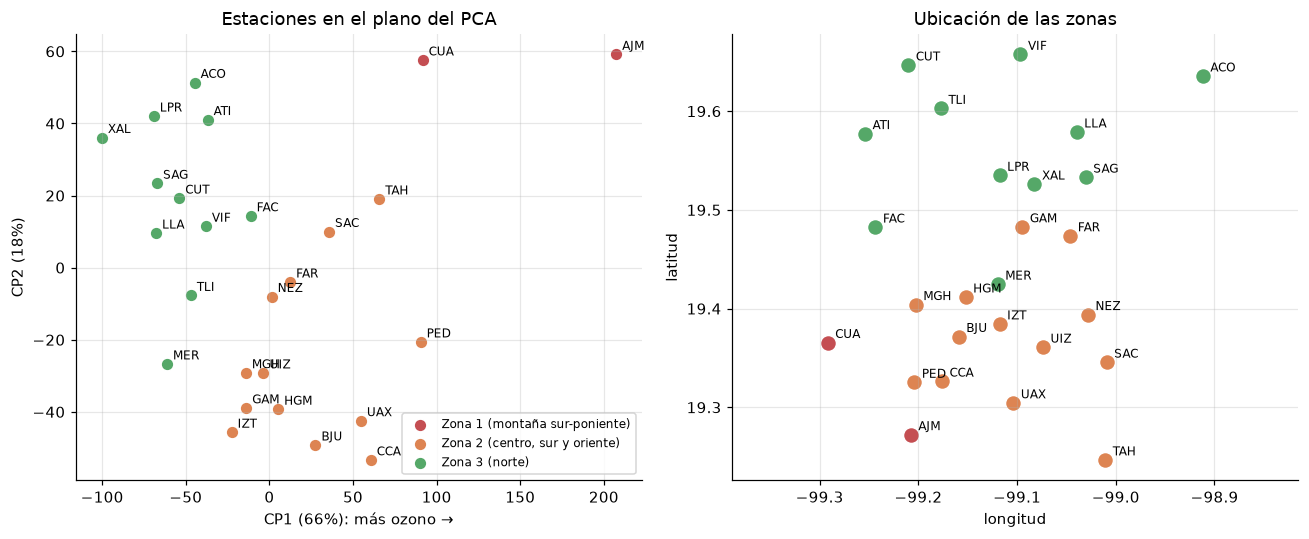

In [6]:
colores = dict(zip(sorted(est["zona_nombre"].unique()), ["#C44E52", "#DD8452", "#55A868", "#4C72B0", "#8172B3", "#937860"]))
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for zn, g in est.groupby("zona_nombre"):
    axs[0].scatter(g["CP1"], g["CP2"], s=70, color=colores[zn], label=zn, edgecolor="white")
    axs[1].scatter(g["lon"], g["lat"], s=110, color=colores[zn], label=zn, edgecolor="white")
    for _, r in g.iterrows():
        axs[0].annotate(r["estacion"], (r["CP1"], r["CP2"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
        axs[1].annotate(r["estacion"], (r["lon"], r["lat"]), xytext=(5, 3), textcoords="offset points", fontsize=8)
axs[0].set(xlabel=f"CP1 ({var[0]:.0%}): más ozono →", ylabel=f"CP2 ({var[1]:.0%})", title="Estaciones en el plano del PCA")
axs[1].set(xlabel="longitud", ylabel="latitud", title="Ubicación de las zonas")
axs[1].set_aspect("equal", adjustable="datalim")
axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "12_zonas_pca_mapa.png", bbox_inches="tight"); plt.show()

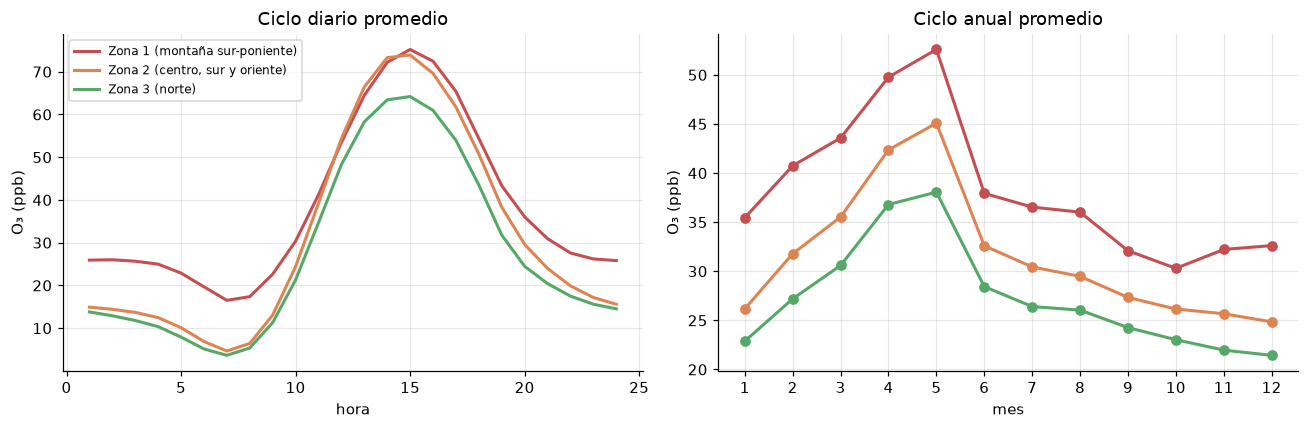

,hora del pico,O₃ en el pico (ppb),% de días con alguna estación > 90 ppb
zona_nombre,,,
Zona 1 (montaña sur-poniente),15,75.2,46.4
"Zona 2 (centro, sur y oriente)",15,73.9,60.8
Zona 3 (norte),15,64.2,42.8


In [7]:
# Cómo es el ozono típico de cada zona
hz = h.merge(est[["estacion", "zona_nombre"]], on="estacion")
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for zn, g in hz.groupby("zona_nombre"):
    g.groupby("hora")["valor"].mean().plot(ax=axs[0], color=colores[zn], lw=2, label=zn)
    g.groupby("mes")["valor"].mean().plot(ax=axs[1], color=colores[zn], lw=2, marker="o", label=zn)
axs[0].set(title="Ciclo diario promedio", xlabel="hora", ylabel="O₃ (ppb)")
axs[1].set(title="Ciclo anual promedio", xlabel="mes", ylabel="O₃ (ppb)", xticks=range(1, 13))
axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "13_perfil_zonas.png", bbox_inches="tight"); plt.show()

pico = hz.groupby(["zona_nombre", "hora"])["valor"].mean().groupby(level=0).agg(["idxmax", "max"])
pico["hora_pico"] = pico["idxmax"].str[1]
dias = (hz.groupby(["zona_nombre", "fecha", "estacion"])["valor"].max().groupby(["zona_nombre", "fecha"]).max() > 90)
display(pd.DataFrame({"hora del pico": pico["hora_pico"], "O₃ en el pico (ppb)": pico["max"].round(1),
                      "% de días con alguna estación > 90 ppb": (dias.groupby(level=0).mean() * 100).round(1)}))

## 4. Clasificación: ¿mañana el máximo de la red rebasará 90 ppb?

**Variable objetivo:** `1` si el máximo de la red del día siguiente es > 90 ppb (límite horario de la NOM-020), `0` si no.

**Variables (todas conocidas al final del día de hoy):**

| Variable | Qué es |
|---|---|
| `max_hoy`, `max_ayer`, `max_antier` | Máximo de la red hoy y los dos días anteriores |
| `media7` | Promedio del máximo de la red en los últimos 7 días |
| `media_red_hoy` | Promedio de las estaciones hoy |
| `hora_max_hoy` | Hora en que ocurrió el máximo de hoy |
| `zona_1_hoy` … | Máximo de hoy en cada zona de la sección 3 |
| `sin_doy`, `cos_doy` | Época del año de mañana (estacionalidad) |
| `dia_*` | Día de la semana de mañana |

**Partición temporal** (nunca aleatoria: se predice el futuro con el pasado):
- Entrenamiento: 2015-2022 · Validación: 2023 (para elegir modelo e hiperparámetros) · Prueba: 2024 en adelante (se usa una sola vez, igual que en el ARIMA).

**Modelos:** referencia de persistencia (“mañana igual que hoy”), regresión logística y bosque aleatorio.

In [8]:
d = pd.read_csv(SALIDA / "o3_diario_red.csv", parse_dates=["fecha"]).set_index("fecha").asfreq("D")
est_dia = h.groupby(["fecha", "estacion"])["valor"].agg(["size", "max"]).reset_index()
est_dia = est_dia[est_dia["size"] >= 18].merge(est[["estacion", "zona"]], on="estacion")
zonas_hoy = est_dia.groupby(["fecha", "zona"])["max"].max().unstack()
zonas_hoy.columns = [f"zona_{z}_hoy" for z in zonas_hoy.columns]
zonas_hoy.index = pd.to_datetime(zonas_hoy.index)

f = pd.DataFrame(index=d.index)
f["max_hoy"] = d["maximo_red"]
f["max_ayer"] = d["maximo_red"].shift(1)
f["max_antier"] = d["maximo_red"].shift(2)
f["media7"] = d["maximo_red"].rolling(7, min_periods=5).mean()
f["media_red_hoy"] = d["media_red"]
f["hora_max_hoy"] = d["hora_max"]
f = f.join(zonas_hoy)
manana = f.index + pd.Timedelta(days=1)
f["sin_doy"] = np.sin(2 * np.pi * manana.day_of_year / 365.25)
f["cos_doy"] = np.cos(2 * np.pi * manana.day_of_year / 365.25)
f = f.join(pd.get_dummies(pd.Series(manana.day_of_week, index=f.index), prefix="dia").astype(int))
f["y"] = (d["maximo_red"].shift(-1) > 90).where(d["maximo_red"].shift(-1).notna())
datos = f.dropna()
VARS = [c for c in datos.columns if c != "y"]
y = datos["y"].astype(int)

tr = datos.index <= "2022-12-31"
va = (datos.index >= "2023-01-01") & (datos.index <= "2023-12-31")
te = datos.index >= "2024-01-01"
print(f"Días utilizables: {len(datos):,} | entrenamiento {tr.sum():,} | validación {va.sum():,} | prueba {te.sum():,}")
print(f"Proporción de días > 90 ppb: entrenamiento {y[tr].mean():.1%} | validación {y[va].mean():.1%} | "
      f"prueba {y[te].mean():.1%}")

Días utilizables: 3,928 | entrenamiento 2,605 | validación 364 | prueba 959
Proporción de días > 90 ppb: entrenamiento 63.7% | validación 65.7% | prueba 70.0%


In [9]:
def metricas(y_real, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {"exactitud": accuracy_score(y_real, pred), "exactitud balanceada": balanced_accuracy_score(y_real, pred),
            "precisión": precision_score(y_real, pred, zero_division=0), "sensibilidad (recall)": recall_score(y_real, pred),
            "F1": f1_score(y_real, pred), "AUC": roc_auc_score(y_real, prob) if len(np.unique(prob)) > 2 else np.nan,
            "Brier": brier_score_loss(y_real, prob)}

Xtr, ytr, Xva, yva = datos.loc[tr, VARS], y[tr], datos.loc[va, VARS], y[va]
candidatos = {}
for C in [0.01, 0.1, 1, 10]:
    candidatos[f"Logística C={C}"] = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
for hoja in [5, 20, 50]:
    candidatos[f"Bosque aleatorio hoja≥{hoja}"] = RandomForestClassifier(
        n_estimators=500, min_samples_leaf=hoja, random_state=SEMILLA, n_jobs=-1)

val, prob_val = {}, {}
for nom, mod in candidatos.items():
    mod.fit(Xtr, ytr)
    prob_val[nom] = mod.predict_proba(Xva)[:, 1]
    val[nom] = metricas(yva, prob_val[nom])
val["Persistencia (mañana = hoy)"] = metricas(yva, (Xva["max_hoy"] > 90).astype(float))
val = pd.DataFrame(val).T
display(val.round(3).sort_values("AUC", ascending=False))
mejor_log = val.filter(like="Logística", axis=0)["AUC"].idxmax()
mejor_rf = val.filter(like="Bosque", axis=0)["AUC"].idxmax()
elegido = val.loc[[mejor_log, mejor_rf], "AUC"].idxmax()
print(f"Mejor logística: {mejor_log} | mejor bosque: {mejor_rf} | elegido por AUC de validación: {elegido}")

# Con ~65 % de días > 90 ppb, el umbral 0.5 inclina al modelo a decir "sí". Regla fija (no se ajusta con datos):
# umbral = proporción de días altos en entrenamiento + validación. Así un "sí" significa "más riesgo que un día típico".
UMBRAL = round(float(y[tr | va].mean()), 2)
print(f"Umbral = proporción de días > 90 ppb en entrenamiento + validación = {UMBRAL:.2f} | "
      f"exactitud balanceada en validación: {balanced_accuracy_score(yva, (prob_val[elegido] >= UMBRAL).astype(int)):.3f} "
      f"(vs {balanced_accuracy_score(yva, (prob_val[elegido] >= 0.5).astype(int)):.3f} con 0.5)")

,exactitud,exactitud balanceada,precisión,sensibilidad (recall),F1,AUC,Brier
Logística C=1,0.761,0.705,0.781,0.883,0.829,0.780,0.172
Logística C=10,0.761,0.705,0.781,0.883,0.829,0.780,0.172
Logística C=0.01,0.758,0.698,0.775,0.891,0.829,0.779,0.172
Logística C=0.1,0.761,0.704,0.779,0.887,0.830,0.779,0.172
Bosque aleatorio hoja≥50,0.747,0.693,0.775,0.866,0.818,0.778,0.174
Bosque aleatorio hoja≥20,0.753,0.699,0.779,0.870,0.822,0.774,0.174
Bosque aleatorio hoja≥5,0.758,0.705,0.783,0.874,0.826,0.771,0.175
Persistencia (mañana = hoy),0.725,0.697,0.793,0.787,0.790,NaN,0.275


Mejor logística: Logística C=10 | mejor bosque: Bosque aleatorio hoja≥50 | elegido por AUC de validación: Logística C=10
Umbral = proporción de días > 90 ppb en entrenamiento + validación = 0.64 | exactitud balanceada en validación: 0.684 (vs 0.705 con 0.5)


### Prueba fuera de muestra (2024 en adelante)

Los dos mejores modelos se reentrenan con entrenamiento + validación y se evalúan **una sola vez** en la prueba: con el umbral convencional de 0.5 y, para el modelo elegido, también con el umbral igual a la proporción de días altos.

,exactitud,exactitud balanceada,precisión,sensibilidad (recall),F1,AUC,Brier
Logística C=10,0.763,0.676,0.794,0.894,0.841,0.806,0.159
"Logística C=10, umbral 0.64",0.746,0.732,0.855,0.766,0.808,0.806,0.159
Bosque aleatorio hoja≥50,0.757,0.667,0.788,0.893,0.837,0.804,0.161
Persistencia (mañana = hoy),0.747,0.700,0.820,0.817,0.819,NaN,0.253


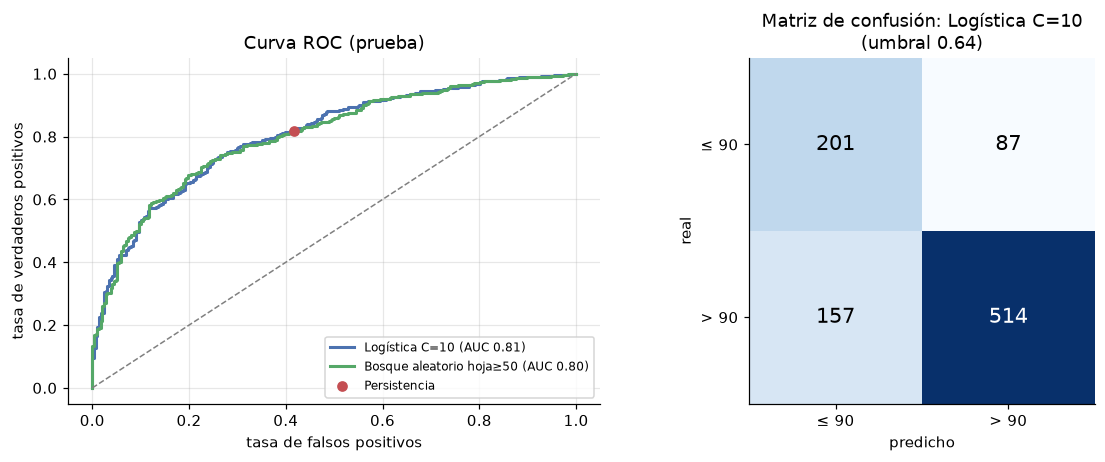

In [10]:
Xtv, ytv, Xte, yte = datos.loc[tr | va, VARS], y[tr | va], datos.loc[te, VARS], y[te]
finales, probs = {}, {}
for nom in [mejor_log, mejor_rf]:
    finales[nom] = candidatos[nom].fit(Xtv, ytv)
    probs[nom] = finales[nom].predict_proba(Xte)[:, 1]
probs["Persistencia (mañana = hoy)"] = (Xte["max_hoy"] > 90).astype(float).to_numpy()
prueba = pd.DataFrame({k: metricas(yte, p) for k, p in probs.items()}).T
ajustado = f"{elegido}, umbral {UMBRAL:.2f}"
prueba.loc[ajustado] = metricas(yte, probs[elegido], UMBRAL)
prueba = prueba.loc[[elegido, ajustado] + [i for i in prueba.index if i not in (elegido, ajustado)]]
display(prueba.round(3))
prueba.round(4).to_csv(RES / "clasificacion_metricas_prueba.csv")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for nom, color in zip([mejor_log, mejor_rf], ["#4C72B0", "#55A868"]):
    fpr, tpr, _ = roc_curve(yte, probs[nom])
    axs[0].plot(fpr, tpr, color=color, lw=2, label=f"{nom} (AUC {prueba.loc[nom, 'AUC']:.2f})")
pp = probs["Persistencia (mañana = hoy)"]
fpr_p = 1 - recall_score(yte, pp, pos_label=0); tpr_p = recall_score(yte, pp)
axs[0].scatter([fpr_p], [tpr_p], color="#C44E52", zorder=3, label="Persistencia")
axs[0].plot([0, 1], [0, 1], "--", color="gray", lw=1)
axs[0].set(xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos", title="Curva ROC (prueba)")
axs[0].legend(fontsize=8, loc="lower right")
cm = confusion_matrix(yte, (probs[elegido] >= UMBRAL).astype(int))
axs[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axs[1].text(j, i, f"{v}", ha="center", va="center", fontsize=14, color="white" if v > cm.max() / 2 else "black")
axs[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["≤ 90", "> 90"], yticklabels=["≤ 90", "> 90"],
           xlabel="predicho", ylabel="real", title=f"Matriz de confusión: {elegido}\n(umbral {UMBRAL:.2f})")
axs[1].grid(False)
fig.tight_layout(); fig.savefig(FIG / "14_clasificacion_roc_confusion.png", bbox_inches="tight"); plt.show()

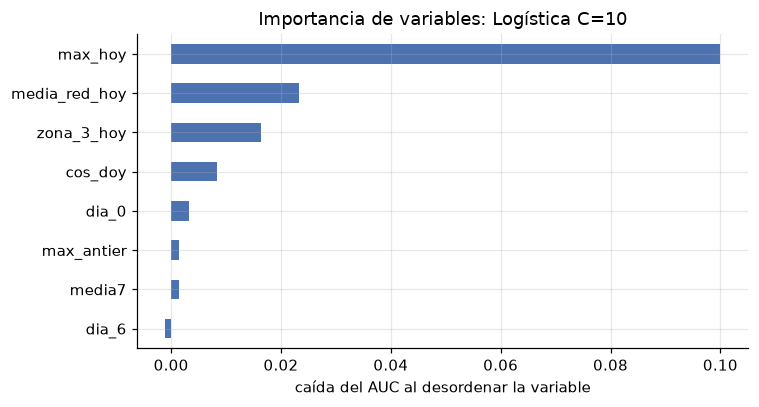

estaciones_pca                                   26
varianza_cp1                                  0.658
varianza_cp2                                  0.184
componentes_90pct                                 3
k_zonas                                           3
silueta                                       0.395
rand_kmeans_vs_ward                             1.0
modelo_clasificacion                 Logística C=10
umbral                                         0.64
prueba_exactitud                              0.746
prueba_exactitud balanceada                   0.732
prueba_F1                                     0.808
prueba_AUC                                    0.806
prueba_Brier                                  0.159
persistencia_exactitud                        0.747
persistencia_exactitud balanceada               0.7
persistencia_F1                               0.819
persistencia_Brier                            0.253
dtype: object

In [11]:
# ¿Qué variables usa el modelo elegido? Importancia por permutación en la prueba
imp = permutation_importance(finales[elegido], Xte, yte, scoring="roc_auc", n_repeats=20, random_state=SEMILLA, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=VARS).sort_values()
imp = imp[imp.abs() > 0.001]
fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp) + 1))
imp.plot.barh(ax=ax, color="#4C72B0")
ax.set(xlabel="caída del AUC al desordenar la variable", title=f"Importancia de variables: {elegido}")
fig.tight_layout(); fig.savefig(FIG / "15_clasificacion_importancia.png", bbox_inches="tight"); plt.show()

pred = pd.DataFrame({"fecha_hoy": Xte.index.date, "fecha_pronostico": (Xte.index + pd.Timedelta(days=1)).date,
                     "real_mayor_90": yte.to_numpy(), "max_hoy": Xte["max_hoy"].to_numpy(),
                     "prob_logistica": probs[mejor_log].round(4), "prob_bosque": probs[mejor_rf].round(4)})
pred["pred_elegido"] = (probs[elegido] >= UMBRAL).astype(int)
pred.to_csv(RES / "clasificacion_predicciones_prueba.csv", index=False)

resumen = {"estaciones_pca": int(perfil.shape[0]), "varianza_cp1": round(float(var[0]), 3),
           "varianza_cp2": round(float(var[1]), 3), "componentes_90pct": n_comp, "k_zonas": K,
           "silueta": round(float(pruebas.loc[K, "silueta"]), 3),
           "rand_kmeans_vs_ward": round(float(adjusted_rand_score(km.labels_, ward.labels_)), 3),
           "modelo_clasificacion": elegido, "umbral": UMBRAL,
           **{f"prueba_{m}": round(float(prueba.loc[ajustado, m]), 3)
              for m in ["exactitud", "exactitud balanceada", "F1", "AUC", "Brier"]},
           **{f"persistencia_{m}": round(float(prueba.loc["Persistencia (mañana = hoy)", m]), 3)
              for m in ["exactitud", "exactitud balanceada", "F1", "Brier"]}}
json.dump(resumen, open(RES / "resumen_zonas_clasificacion.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
pd.Series(resumen)

## 5. Lectura y conclusiones

**Reducción dimensional (PCA)**
- Tres componentes resumen el 91 % de las diferencias entre estaciones (288 variables → 3).
- **CP1 (66 %) = cuánto ozono tiene la estación.** Todas sus cargas son positivas y se correlaciona 1.00 con el promedio de la estación. Pesa sobre todo en las madrugadas de la temporada seca y en las tardes de la temporada de lluvias.
- **CP2 (18 %) = qué tan marcado es el pico de la tarde.** Carga negativa de 11 a 18 h y positiva de noche. Valores altos indican un ciclo más plano, con más ozono relativo de madrugada (correlación 0.61 con la razón madrugada/tarde). Físicamente: donde hay mucho tráfico, el NO de la noche "consume" el ozono, y el ciclo diario es muy marcado.

**Clusterización (K-means, k = 3)**
- k = 3 es la única solución **estable**: K-means y Ward forman exactamente los mismos grupos (Rand ajustado = 1.00), con una silueta de 0.40, casi igual a la mejor (0.41 con k = 2, que no es estable: Rand 0.18).
- **Zona 1, montaña sur-poniente (Ajusco Medio y Cuajimalpa):** la que más ozono tiene (38 ppb de promedio) y la que más conserva de noche. Están en altura y lejos del tráfico, así que el ozono no se destruye de madrugada.
- **Zona 2, centro, sur y oriente (13 estaciones):** pico de tarde muy marcado (74 ppb a las 15 h) y la mayor frecuencia de días con alguna estación sobre la NOM (61 %). Es la zona que recibe la masa de aire contaminada durante la tarde.
- **Zona 3, norte (11 estaciones):** la de menos ozono (27 ppb; pico de 64 ppb) y la menor frecuencia de días sobre la NOM (43 %). Incluye a **Merced**, que está en el centro pero tiene el patrón del norte: es la estación con más NO local (la menor razón madrugada/tarde, 0.11).
- Las zonas salen **solo de los datos de ozono**, sin usar coordenadas, y aun así quedan geográficamente compactas en el mapa: eso respalda que son zonas reales.

**Clasificación (¿mañana > 90 ppb?)**
- En la prueba (2024 en adelante, 1,007 días, 70 % de días altos) la regresión logística tiene AUC 0.81 y Brier 0.159. Sus **probabilidades son 37 % más precisas** que la persistencia (Brier 0.253). El bosque aleatorio queda prácticamente empatado (AUC 0.80): la relación es casi lineal y un modelo más flexible no aporta.
- **La decisión sí/no depende del umbral:**
  - Con 0.5, el modelo dice "sí" casi siempre (sensibilidad 0.89) y su exactitud balanceada (0.68) queda por debajo de la persistencia (0.70).
  - Con el umbral igual a la proporción de días altos (0.64), supera a la persistencia en exactitud balanceada (0.73 vs 0.70) y en precisión (0.86 vs 0.82), con la misma exactitud (0.75).
- **Qué usa el modelo:** sobre todo el máximo de hoy, luego el promedio de la red y el máximo de la zona norte, y la época del año. Las zonas de la sección 3 aportan información útil para el pronóstico.
- **Coherencia con el ARIMA:** el ARIMA del notebook 2 llega a un AUC de 0.81 para el mismo evento. Dos enfoques distintos topan en el mismo techo: sin meteorología (temperatura, radiación, viento) no se puede anticipar mucho mejor.

**Limitaciones**
- 26 estaciones es una muestra chica para clusterizar; por eso se exigió estabilidad entre métodos.
- La clasificación usa umbral fijo; en la práctica el umbral depende del costo de una falsa alarma frente al de no avisar.